In [1]:
# CELL 1 — imports and shared settings
import os, zipfile, json, time, random, gc
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (f1_score, cohen_kappa_score,
                             confusion_matrix, classification_report)
import matplotlib.pyplot as plt

# SAME values as the weighted-CE and sampler runs (only the imbalance handling differs).
SEED = 42
IMAGE_SIZE = 512
BATCH_SIZE = 16
ACCUM_STEPS = 2             # Effective batch ~32; gradient accum. != BN batch 32
MAX_EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_HFLIP = True            # Only during training
USE_ROTATION = False        # Confirm shared augmentation with team
NUM_WORKERS = 2
CHECKPOINT_METRIC = 'macro_f1'  # Same metric MUST be used by control + weighted CE

INPUT_ZIP = Path('/kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/_output_.zip')
DATA_ROOT = Path('/kaggle/working/oculus_stage2_data')
OUTPUT_DIR = Path('/kaggle/working/oculus_stage2_resnet18_bg_control')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
assert torch.cuda.is_available(), 'Enable a GPU accelerator in Kaggle Settings.'
DEVICE = torch.device('cuda')
assert IMAGE_SIZE == 512
assert CHECKPOINT_METRIC == 'macro_f1'
print('GPU:', torch.cuda.get_device_name(0))
print('Oculus | Stage 2 | ResNet-18 BG | CONTROL: plain CE, no class weights, no sampler')
print('Output:', OUTPUT_DIR)

GPU: Tesla T4
Oculus | Stage 2 | ResNet-18 BG | CONTROL: plain CE, no class weights, no sampler
Output: /kaggle/working/oculus_stage2_resnet18_bg_control


In [2]:
# CELL 2 — extract only the Ben Graham preprocessing and manifest
assert INPUT_ZIP.is_file(), f'Attach the Kaggle 02-preprocessing output: {INPUT_ZIP}'
DATA_ROOT.mkdir(parents=True, exist_ok=True)
root = DATA_ROOT.resolve()
with zipfile.ZipFile(INPUT_ZIP) as z:
    to_extract = []
    for info in z.infolist():
        name = info.filename
        if name != 'manifest_v2.csv' and not name.startswith('processed_bg/'):
            continue
        dest = (DATA_ROOT / name).resolve()
        assert dest.is_relative_to(root), f'Unsafe archive member: {name}'
        assert ((info.external_attr >> 16) & 0o170000) != 0o120000, f'Symlink: {name}'
        if not info.is_dir() and not dest.exists():
            to_extract.append(info)
    print('Extracting', len(to_extract), 'missing files ...', flush=True)
    z.extractall(DATA_ROOT, members=to_extract)
assert (DATA_ROOT / 'manifest_v2.csv').is_file(), 'Manifest missing after extraction'
print('Extraction complete')

Extracting 88840 missing files ...
Extraction complete


In [3]:
# CELL 3 — keep DR grades 1–4 in pre-existing patient-separated splits
manifest = pd.read_csv(DATA_ROOT / 'manifest_v2.csv')
required = {'filename', 'split', 'grade', 'group_id', 'load_ok', 'excluded_reason'}
assert required.issubset(manifest), f'Missing columns: {required - set(manifest)}'
valid_rows = (manifest['load_ok'].astype(str).str.lower().eq('true')
              & manifest['excluded_reason'].isna()
              & manifest['split'].isin(['train', 'val', 'test']))
df = manifest.loc[valid_rows].copy()
df['grade'] = pd.to_numeric(df['grade'], errors='coerce')
df = df[df['grade'].isin([1, 2, 3, 4])].copy().reset_index(drop=True)
df['grade'] = df['grade'].astype(int)
df['target'] = df['grade'] - 1  # CE uses internal labels 0..3, reports use 1..4
assert df['group_id'].notna().all(), 'Missing patient/group IDs'
assert df.groupby('group_id')['split'].nunique().max() == 1, 'Group leakage across splits'

splits = {name: df.loc[df['split'] == name].reset_index(drop=True)
          for name in ('train', 'val', 'test')}
for split, frame in splits.items():
    print(split, 'images:', len(frame), '| grades:', frame['grade'].value_counts().sort_index().to_dict())
    assert frame['grade'].nunique() == 4, f'{split}: missing one or more DR grades'
    missing = [str(DATA_ROOT / 'processed_bg' / split / f)
               for f in frame['filename'] if not (DATA_ROOT / 'processed_bg' / split / f).is_file()]
    assert not missing, f'{split}: missing {len(missing)} image files, e.g. {missing[:3]}'

EXPECTED_TRAIN = {1: 2982, 2: 9922, 3: 713, 4: 1544}
actual_train = splits['train']['grade'].value_counts().sort_index().to_dict()
assert actual_train == EXPECTED_TRAIN, f'Training counts differ from team plan: {actual_train}'
assert int((splits['test']['grade'] == 3).sum()) == 76, 'Expected 76 grade-3 test images'
SAMPLES_PER_EPOCH = len(splits['train'])  # Every training image once per epoch (no replacement)
assert SAMPLES_PER_EPOCH == 15161
print('Dataset checks passed; sample count per epoch:', SAMPLES_PER_EPOCH)

train images: 15161 | grades: {1: 2982, 2: 9922, 3: 713, 4: 1544}
val images: 1591 | grades: {1: 289, 2: 1035, 3: 99, 4: 168}
test images: 1584 | grades: {1: 348, 2: 1004, 3: 76, 4: 156}
Dataset checks passed; sample count per epoch: 15161


In [4]:
# CELL 4 — on-the-fly TRAIN-ONLY augmentation; plain shuffled loader (NO sampler)
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_ops = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
if USE_HFLIP:
    train_ops.append(transforms.RandomHorizontalFlip(p=0.5))
if USE_ROTATION:
    train_ops.append(transforms.RandomRotation(10))
train_ops += [transforms.ToTensor(), normalize]
eval_ops = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(), normalize]

class GradingDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)
        self.transform = transforms.Compose(train_ops if training else eval_ops)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = DATA_ROOT / 'processed_bg' / row['split'] / row['filename']
        with Image.open(path) as image:
            x = self.transform(image.convert('RGB'))
        return x, torch.tensor(int(row['target']), dtype=torch.long)

train_counts = splits['train']['target'].value_counts().sort_index()
assert train_counts.index.tolist() == [0, 1, 2, 3]
# CONTROL: NO sampler and NO class weights. Plain shuffle over the natural class counts.
train_loader = DataLoader(
    GradingDataset(splits['train'], training=True),
    batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    GradingDataset(splits['val'], training=False),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

# Training distribution stays NATURAL (imbalanced) - nothing is re-balanced in the control run.
print('Training grade distribution (natural, expect ~20% / 65% / 5% / 10%):',
      splits['train']['grade'].value_counts(normalize=True).sort_index().round(3).to_dict())
x_check, y_check = next(iter(val_loader))
assert tuple(x_check.shape[-2:]) == (512, 512)
print('Validation image shape:', tuple(x_check.shape))
print('Training images per epoch:', SAMPLES_PER_EPOCH, '| train batches:', len(train_loader))

Training grade distribution (natural, expect ~20% / 65% / 5% / 10%): {1: 0.197, 2: 0.654, 3: 0.047, 4: 0.102}
Validation image shape: (16, 3, 512, 512)
Training images per epoch: 15161 | train batches: 948


In [5]:
# CELL 5 — pretrained ResNet-18 and plain UNWEIGHTED CrossEntropyLoss
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, 4)
model = model.to(DEVICE)
for parameter in model.parameters():
    parameter.requires_grad = True  # End-to-end tuning (same as the other Stage 2 runs)

loss_fn = nn.CrossEntropyLoss()       # NO class weights and NO softmax before loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                               weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler('cuda')
print('Model: ResNet-18, outputs:', model.fc.out_features)
print('Optimizer: AdamW | WD:', WEIGHT_DECAY, '| LR:', LEARNING_RATE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]


Model: ResNet-18, outputs: 4
Optimizer: AdamW | WD: 0.0001 | LR: 0.0001


In [6]:
# CELL 6 — metrics calculated on the natural val/test distribution
@torch.inference_mode()
def evaluate(loader):
    model.eval()
    labels, predicted, scores = [], [], []
    total_loss, n = 0.0, 0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(images)
        total_loss += loss_fn(logits.float(), targets).item() * len(targets)
        n += len(targets)
        # Softmax only during EVALUATION; CrossEntropyLoss itself takes raw logits.
        probs = torch.softmax(logits.float(), dim=1).cpu().numpy()
        labels.append(targets.cpu().numpy())
        predicted.append(probs.argmax(axis=1))
        scores.append(probs)
    y = np.concatenate(labels)
    p = np.concatenate(predicted)
    probs = np.concatenate(scores)
    metrics = {
        'loss': float(total_loss / n),
        'macro_f1': float(f1_score(y, p, labels=[0, 1, 2, 3],
                                   average='macro', zero_division=0)),
        'qwk': float(cohen_kappa_score(y, p, labels=[0, 1, 2, 3],
                                       weights='quadratic')),
        'per_grade_recall': {
            str(grade): float((p[y == grade - 1] == grade - 1).mean())
            for grade in (1, 2, 3, 4)
        },
        'confusion_matrix': confusion_matrix(y, p, labels=[0, 1, 2, 3]).tolist(),
    }
    return metrics, y, p, probs


def per_source_metrics(frame, y, p):
    """For bias checks. NOT a second training experiment."""
    if 'source' not in frame:
        print('No source column; per-source breakdown unavailable')
        return {}
    source = frame['source'].fillna('unknown').astype(str).to_numpy()
    results = {}
    for name in sorted(set(source)):
        mask = source == name
        ys, ps = y[mask], p[mask]
        results[name] = {
            'n': int(mask.sum()),
            'grade_counts': {str(g): int((ys == g-1).sum()) for g in (1,2,3,4)},
            'macro_f1': float(f1_score(ys, ps, labels=[0,1,2,3],
                                       average='macro', zero_division=0)),
            'qwk': float(cohen_kappa_score(ys, ps, labels=[0,1,2,3],
                                           weights='quadratic')),
            'per_grade_recall': {str(g): (float((ps[ys==g-1]==g-1).mean())
                                         if np.any(ys==g-1) else None)
                                 for g in (1,2,3,4)},
        }
    return results

In [7]:
# CELL 7 — train; checkpoint chosen using VALIDATION macro-F1 only
history = []
best_score, best_epoch, stagnant_epochs = -1.0, None, 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    started = time.time()
    train_loss_total, seen = 0.0, 0
    optimizer.zero_grad(set_to_none=True)
    for step, (images, targets) in enumerate(train_loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(images)
        loss = loss_fn(logits.float(), targets)
        # Last accumulation group can have fewer than ACCUM_STEPS batches.
        group_first = ((step - 1) // ACCUM_STEPS) * ACCUM_STEPS + 1
        group_size = min(ACCUM_STEPS, len(train_loader) - group_first + 1)
        scaler.scale(loss / group_size).backward()
        if step % ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        train_loss_total += loss.item() * len(targets)
        seen += len(targets)

    val_metrics, _, _, _ = evaluate(val_loader)
    row = {
        'epoch': epoch,
        'train_loss': train_loss_total / seen,
        'val_loss': val_metrics['loss'],
        'val_macro_f1': val_metrics['macro_f1'],
        'val_qwk': val_metrics['qwk'],
        'val_per_grade_recall': json.dumps(val_metrics['per_grade_recall']),
        'sec_per_epoch': round(time.time() - started, 1),
    }
    history.append(row)
    pd.DataFrame(history).to_csv(OUTPUT_DIR / 'history.csv', index=False)
    print('EPOCH', epoch, '|', row, flush=True)

    score = val_metrics[CHECKPOINT_METRIC]
    if score > best_score:
        best_score, best_epoch, stagnant_epochs = score, epoch, 0
        torch.save({
            'state_dict': model.state_dict(),
            'epoch': epoch,
            'validation': val_metrics,
            'config': {'seed': SEED, 'image_size': IMAGE_SIZE,
                       'optimizer': 'AdamW', 'lr': LEARNING_RATE,
                       'weight_decay': WEIGHT_DECAY, 'batch': BATCH_SIZE,
                       'accum_steps': ACCUM_STEPS,
                       'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
                       'training_samples_per_epoch': SAMPLES_PER_EPOCH,
                       'use_hflip': USE_HFLIP, 'use_rotation': USE_ROTATION,
                       'checkpoint_metric': CHECKPOINT_METRIC,
                       'loss': 'plain_cross_entropy_no_class_weights',
                       'sampling': 'none_plain_shuffle'},
        }, OUTPUT_DIR / 'best_model.pt')
    else:
        stagnant_epochs += 1
    if stagnant_epochs >= PATIENCE:
        print('Early stopping after epoch', epoch)
        break
print('Best epoch:', best_epoch, '| val macro-F1:', best_score)

EPOCH 1 | {'epoch': 1, 'train_loss': 0.7475656655397573, 'val_loss': 0.662666951014065, 'val_macro_f1': 0.552195464684736, 'val_qwk': 0.609846509817535, 'val_per_grade_recall': '{"1": 0.4913494809688581, "2": 0.8685990338164251, "3": 0.1717171717171717, "4": 0.5297619047619048}', 'sec_per_epoch': 126.5}
EPOCH 2 | {'epoch': 2, 'train_loss': 0.6487973617788717, 'val_loss': 0.661484111898879, 'val_macro_f1': 0.5533682740013677, 'val_qwk': 0.660540890962132, 'val_per_grade_recall': '{"1": 0.30103806228373703, "2": 0.9053140096618357, "3": 0.21212121212121213, "4": 0.7261904761904762}', 'sec_per_epoch': 129.1}
EPOCH 3 | {'epoch': 3, 'train_loss': 0.5989379302177319, 'val_loss': 0.6857670896237635, 'val_macro_f1': 0.5466313135858776, 'val_qwk': 0.5963504858925152, 'val_per_grade_recall': '{"1": 0.5674740484429066, "2": 0.8444444444444444, "3": 0.13131313131313133, "4": 0.5}', 'sec_per_epoch': 127.9}
EPOCH 4 | {'epoch': 4, 'train_loss': 0.5245991181976586, 'val_loss': 0.693601899406282, 'val_

BEST CHECKPOINT | epoch: 6
VALIDATION RESULTS: {
  "loss": 0.7720920430797215,
  "macro_f1": 0.5771851964730974,
  "qwk": 0.6531369863527934,
  "per_grade_recall": {
    "1": 0.6401384083044983,
    "2": 0.770048309178744,
    "3": 0.1919191919191919,
    "4": 0.7023809523809523
  },
  "confusion_matrix": [
    [
      185,
      102,
      0,
      2
    ],
    [
      196,
      797,
      8,
      34
    ],
    [
      2,
      59,
      19,
      19
    ],
    [
      6,
      37,
      7,
      118
    ]
  ]
}
Per-grade validation report:
              precision    recall  f1-score   support

           1       0.48      0.64      0.55       289
           2       0.80      0.77      0.79      1035
           3       0.56      0.19      0.29        99
           4       0.68      0.70      0.69       168

    accuracy                           0.70      1591
   macro avg       0.63      0.58      0.58      1591
weighted avg       0.71      0.70      0.70      1591



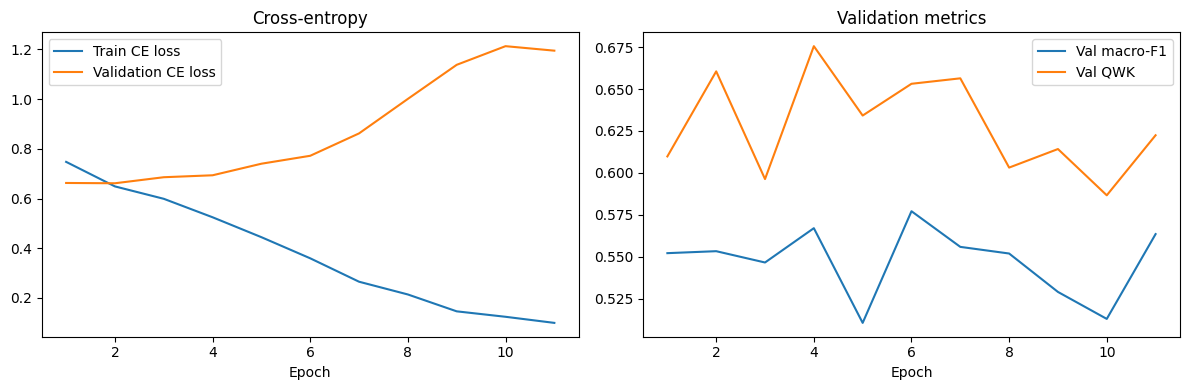

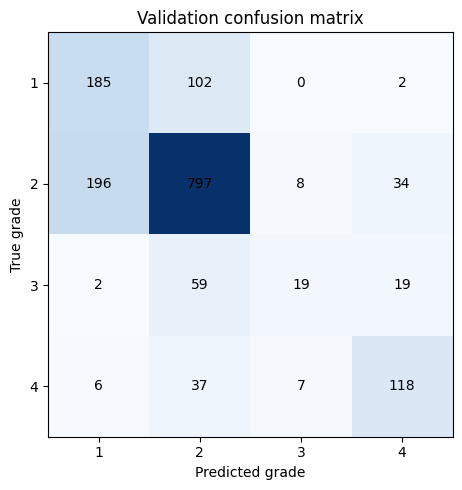

Validation outputs saved: /kaggle/working/oculus_stage2_resnet18_bg_control


In [8]:
# CELL 8 — validation results from best checkpoint; save plots + predictions
best = torch.load(OUTPUT_DIR / 'best_model.pt', map_location=DEVICE, weights_only=True)
model.load_state_dict(best['state_dict'])
val_metrics, val_y, val_pred, val_probs = evaluate(val_loader)
print('BEST CHECKPOINT | epoch:', best['epoch'])
print('VALIDATION RESULTS:', json.dumps(val_metrics, indent=2))
(OUTPUT_DIR / 'validation_metrics.json').write_text(json.dumps({
    'best_epoch': best['epoch'], **val_metrics,
    'per_source': per_source_metrics(splits['val'], val_y, val_pred),
}, indent=2))

val_predictions = splits['val'][['filename', 'group_id', 'grade']].copy()
if 'source' in splits['val']:
    val_predictions['source'] = splits['val']['source']
val_predictions['predicted_grade'] = val_pred + 1
for idx in range(4):
    val_predictions[f'prob_grade_{idx + 1}'] = val_probs[:, idx]
val_predictions.to_csv(OUTPUT_DIR / 'validation_predictions.csv', index=False)
print('Per-grade validation report:')
print(classification_report(val_y + 1, val_pred + 1, labels=[1,2,3,4], zero_division=0))

h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h['epoch'], h['train_loss'], label='Train CE loss')
axes[0].plot(h['epoch'], h['val_loss'], label='Validation CE loss')
axes[0].legend(); axes[0].set_xlabel('Epoch'); axes[0].set_title('Cross-entropy')
axes[1].plot(h['epoch'], h['val_macro_f1'], label='Val macro-F1')
axes[1].plot(h['epoch'], h['val_qwk'], label='Val QWK')
axes[1].legend(); axes[1].set_xlabel('Epoch'); axes[1].set_title('Validation metrics')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'validation_training_curves.png', dpi=160); plt.show()
cm = np.array(val_metrics['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
for (i, j), count in np.ndenumerate(cm):
    ax.text(j, i, str(count), ha='center', va='center')
ax.set_xticks(range(4), [1,2,3,4]); ax.set_yticks(range(4), [1,2,3,4])
ax.set_xlabel('Predicted grade'); ax.set_ylabel('True grade')
ax.set_title('Validation confusion matrix')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'validation_confusion_matrix.png', dpi=160); plt.show()
print('Validation outputs saved:', OUTPUT_DIR)

In [9]:
# CELL 9 — FINAL TEST (run once, using the best validation checkpoint)
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test_loader = DataLoader(
        GradingDataset(splits['test'], training=False),
        batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=True,
        persistent_workers=(NUM_WORKERS > 0),
    )
    checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt', map_location=DEVICE,
                            weights_only=True)
    model.load_state_dict(checkpoint['state_dict'])
    test_metrics, test_y, test_pred, test_probs = evaluate(test_loader)
    detailed = {'best_epoch': checkpoint['epoch'], **test_metrics,
                'per_source': per_source_metrics(splits['test'], test_y, test_pred)}
    (OUTPUT_DIR / 'test_metrics.json').write_text(json.dumps(detailed, indent=2))
    output = splits['test'][['filename', 'group_id', 'grade']].copy()
    if 'source' in splits['test']:
        output['source'] = splits['test']['source']
    output['predicted_grade'] = test_pred + 1
    for idx in range(4):
        output[f'prob_grade_{idx+1}'] = test_probs[:, idx]
    output.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
    print('FINAL TEST:', json.dumps(detailed, indent=2))
    print(classification_report(test_y+1, test_pred+1,
                                labels=[1,2,3,4], zero_division=0))
else:
    print('Test set NOT evaluated. Choose your configuration using validation first.')

FINAL TEST: {
  "best_epoch": 6,
  "loss": 0.7976754732204206,
  "macro_f1": 0.5774923618091873,
  "qwk": 0.640900857959962,
  "per_grade_recall": {
    "1": 0.6350574712643678,
    "2": 0.7659362549800797,
    "3": 0.2236842105263158,
    "4": 0.6410256410256411
  },
  "confusion_matrix": [
    [
      221,
      125,
      0,
      2
    ],
    [
      195,
      769,
      10,
      30
    ],
    [
      1,
      37,
      17,
      21
    ],
    [
      5,
      45,
      6,
      100
    ]
  ],
  "per_source": {
    "APTOS": {
      "n": 135,
      "grade_counts": {
        "1": 26,
        "2": 65,
        "3": 19,
        "4": 25
      },
      "macro_f1": 0.5154731457800512,
      "qwk": 0.5820433436532508,
      "per_grade_recall": {
        "1": 0.5769230769230769,
        "2": 0.7692307692307693,
        "3": 0.15789473684210525,
        "4": 0.56
      }
    },
    "EyePACS": {
      "n": 1449,
      "grade_counts": {
        "1": 322,
        "2": 939,
        "3": 57,
   